In [2]:
import random
from rdkit import Chem
from rdkit.Chem.Scaffolds import MurckoScaffold

In [18]:
def get_scaffold(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None

    scaffold = MurckoScaffold.MurckoScaffoldSmiles(
        mol = mol,
        includeChirality = False
    )

    # Group acyclic molecules under one fallback group
    if scaffold == "":
        scaffold = "ACYCLIC"

    return scaffold

In [19]:
def scaffold_split(smiles_list, fractions = (0.8, 0.1, 0.1), seed = 42 ):
    assert abs(sum(fractions) - 1.0) < 1e-8

    scaffold_groups = {}
    for idx, smiles in enumerate(smiles_list):
        scaffold = get_scaffold(smiles)

        if scaffold is None:
            raise ValueError(f"Invalid SMILES at index {idx} : {smiles}")

        scaffold_groups.setdefault(scaffold, []).append(idx)

    groups = list(scaffold_groups.values())

    # Deterministic shuffle to break equal-size group ties.
    rng = random.Random(seed)
    rng.shuffle(groups)

    # Larger groups are allocated first.
    groups.sort(key=len, reverse=True)

    n = len(smiles_list)

    targets = [
        fractions[0] * n,
        fractions[1] * n,
        fractions[2] * n
    ]

    assigned = [[], [], []]

    for group in groups:
        # Choose the split whose relative dificit is largest.
        deficits = [
            targets[i] - len(assigned[i])
            for i in range(3)
        ]

        split_idx = max(range(3), key=lambda i: deficits[i])

        assigned[split_idx].extend(group)

    train_idx, val_idx, test_idx = assigned

    return train_idx, val_idx, test_idx

In [24]:
def verify_scaffold_split(smiles_list, splits):
    scaffold_sets = []

    for indices in splits:
        scaffolds = {
            get_scaffold(smiles_list[i])
            for i in indices
        }
        scaffold_sets.append(scaffolds)

    train_scaffolds = scaffold_sets[0]
    val_scaffolds = scaffold_sets[1]
    test_scaffolds = scaffold_sets[2]

    print("Train scaffolds: ", len(train_scaffolds))
    print("Validation scaffolds: ", len(val_scaffolds))
    print("Test scaffolds: ", len(test_scaffolds))

    print("Train/validation overlap:", 
          len(train_scaffolds & val_scaffolds)
          )
    print("Train/test overlap", len(train_scaffolds & test_scaffolds))
    print("Validation/test overlap", len(val_scaffolds & test_scaffolds))

    assert not ( train_scaffolds & val_scaffolds)
    assert not (train_scaffolds & test_scaffolds)
    assert not (val_scaffolds & test_scaffolds)
    print("Scaffold leakage check passed")

In [8]:
import os
import json
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch_geometric.datasets import MoleculeNet
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GCNConv, global_mean_pool

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

#from split_utils import scaffold_split, verify_scaffold_split

In [9]:
# =================================================
# CONFIGURATION
#==================================================

SEED = 42
EPOCHS = 200
BATCH_SIZE = 32
LEARNING_RATE = 0.001
HIDDEN_CHANNELS = 128

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device: ", DEVICE)

Device:  cpu


In [10]:
#===========================================================
# 2. REPRODUCIBILITY
#===========================================================
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

#================================================
# FOLDERS
#================================================
os.makedirs("data", exist_ok=True)
os.makedirs("models", exist_ok=True)
os.makedirs("results", exist_ok=True)

In [15]:
#=======================================
# LOAD ESOL
#=======================================
dataset = MoleculeNet(root="data/ESOL", name="ESOL")

smiles_list = list(dataset.smiles)
print("Dataset size: ", len(dataset))
print(smiles_list[0])

Dataset size:  1128
OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)C(O)C3O 


In [26]:
#=====================================================
# SCAFFOLD SPLIT
#=====================================================
train_idx, val_idx, test_idx = scaffold_split(smiles_list, fractions=(0.8, 0.1, 0.1), seed=SEED)

verify_scaffold_split(smiles_list, [train_idx, val_idx, test_idx])

print("\n Split sizes:")
print("Train: ", len(train_idx))
print("Validation:", len(val_idx))
print("Test:", len(test_idx))

# Save indices for reproducibility and fair comparison
with open("results/split_indices.json", 'w') as f:
    json.dump(
        {
            "train" : train_idx,
            "validation" : val_idx,
            "test" : test_idx
        },
        f,
        indent=4
    )

Train scaffolds:  103
Validation scaffolds:  83
Test scaffolds:  83
Train/validation overlap: 0
Train/test overlap 0
Validation/test overlap 0
Scaffold leakage check passed

 Split sizes:
Train:  902
Validation: 113
Test: 113


In [27]:
#======================================================
# DATA LOADERS
#======================================================
train_dataset = [dataset[i] for i in train_idx]
val_dataset = [dataset[i] for i in val_idx]
test_dataset = [dataset[i] for i in test_idx]

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

In [34]:
#=================================================================
# GCN ARCHITECTURE
#=================================================================

class MolecularGCN(nn.Module):

    def __init__(self, feature_sizes, hidden_channels=128):
        super().__init__()
        self.embedding = nn.ModuleList([
            nn.Embedding(size, hidden_channels) for size in feature_sizes
        ])

        self.conv1 = GCNConv(hidden_channels, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, hidden_channels)

        self.fc1 = nn.Linear(hidden_channels, hidden_channels)
        self.fc2 = nn.Linear(hidden_channels, 1)

        self.dropout = 0.2

    def forward(self, x, edge_index, batch):
        h = 0

        for column, embedding in enumerate(self.embedding):
            h = h + embedding(x[:, column])

        h = self.conv1(h, edge_index)
        h = F.relu(h)

        h = self.conv2(h, edge_index)
        h = F.relu(h)

        h = global_mean_pool(h, batch)

        h = F.dropout(h, p=self.dropout, training=self.training)

        h = F.relu(self.fc1(h))
        h = self.fc2(h)

        return h.view(-1)


In [36]:
#====================================================
# MODEL
#====================================================

feature_sizes = [
    int(dataset.data.x[:, i].max().item()) + 1
    for i in range(dataset.data.x.shape[1])
]

model = MolecularGCN(feature_sizes, hidden_channels=HIDDEN_CHANNELS).to(DEVICE)

optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)

loss_function = nn.MSELoss()

C:\Users\mulpu\AppData\Local\Temp\ipykernel_37848\965215127.py:7: UserWarning: It is not recommended to directly access the internal storage format `data` of an 'InMemoryDataset'. If you are absolutely certain what you are doing, access the internal storage via `InMemoryDataset._data` instead to suppress this warning. Alternatively, you can access stacked individual attributes of every graph via `dataset.{attr_name}`.
  for i in range(dataset.data.x.shape[1])
C:\Users\mulpu\AppData\Local\Temp\ipykernel_37848\965215127.py:6: UserWarning: It is not recommended to directly access the internal storage format `data` of an 'InMemoryDataset'. If you are absolutely certain what you are doing, access the internal storage via `InMemoryDataset._data` instead to suppress this warning. Alternatively, you can access stacked individual attributes of every graph via `dataset.{attr_name}`.
  int(dataset.data.x[:, i].max().item()) + 1


In [37]:
#====================================================
# TRAIN
#===================================================

def train_epoch(loader):
    model.train()

    total_loss = 0
    total_graphs = 0

    for batch in loader:
        batch = batch.to(DEVICE)
        optimizer.zero_grad()
        predictions = model(batch.x, batch.edge_index, batch.batch)
        targets = batch.y.view(-1)
        loss = loss_function(predictions, targets)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * batch.num_graphs
        total_graphs += batch.num_graphs

    return total_loss / total_graphs

In [40]:
# = =========================================
# EVALUATION
#=============================================

@torch.no_grad()
def evaluate(loader):
    model.eval()

    predictions = []
    targets = []

    for batch in loader :
        batch = batch.to(DEVICE)
        output = model(batch.x, batch.edge_index, batch.batch)

        predictions.extend(output.cpu().numpy())

        targets.extend(batch.y.view(-1).cpu().numpy())

    predictions = np.array(predictions)
    targets = np.array(targets)

    mae = mean_absolute_error(targets, predictions)
    rmse = np.sqrt(mean_squared_error(targets, predictions))
    r2 = r2_score(targets, predictions)

    return mae, rmse, r2, predictions, targets

In [41]:
#==============================================================
# TRAINING LOOP + HISTORY
#==============================================================

history = []
best_val_mae = float("inf")
best_epoch = 0

for epoch in range(1, EPOCHS + 1):
    train_loss = train_epoch(train_loader)
    train_mae, train_rmse, train_r2, _, _ = evaluate(train_loader)
    val_mae, val_rmse, val_r2, _, _ = evaluate(val_loader)

    history.append({
        "epoch" : epoch,
        "train_loss" : train_loss,
        "train_mae" : train_mae,
        "train_rmse" : train_rmse,
        "train_r2" : train_r2,
        "val_mae" : val_mae,
        "val_rmse" : val_rmse,
        "val_r2" : val_r2
    })

    if val_mae < best_val_mae:
        best_val_mae = val_mae
        best_epoch = epoch

        torch.save(
            model.state_dict(),
            "models/best_gcn.pt"
        )

    if epoch % 10 == 0 or epoch == 1:
        print(
            f"Epoch {epoch:03d} |"
            f"Train Loss {train_loss:.4f} |"
            f"Train MAE {train_mae:.4f} |"
            f"Val MAE {val_mae:.4f} |"
            f"Val RMSE {val_rmse:.4f} |"
            f"Val R2 {val_r2:.4f}"
        )

Epoch 001 |Train Loss 3.7387 |Train MAE 1.4035 |Val MAE 1.4589 |Val RMSE 1.8733 |Val R2 0.1784
Epoch 010 |Train Loss 1.6009 |Train MAE 0.8757 |Val MAE 1.2005 |Val RMSE 1.5418 |Val R2 0.4434
Epoch 020 |Train Loss 1.2725 |Train MAE 0.8416 |Val MAE 1.3695 |Val RMSE 1.7263 |Val R2 0.3022
Epoch 030 |Train Loss 0.8000 |Train MAE 0.7050 |Val MAE 1.1778 |Val RMSE 1.5166 |Val R2 0.4615
Epoch 040 |Train Loss 0.8790 |Train MAE 0.5437 |Val MAE 0.9392 |Val RMSE 1.2662 |Val R2 0.6246
Epoch 050 |Train Loss 0.6451 |Train MAE 0.5201 |Val MAE 0.8530 |Val RMSE 1.1154 |Val R2 0.7087
Epoch 060 |Train Loss 0.6306 |Train MAE 0.4932 |Val MAE 0.9209 |Val RMSE 1.1880 |Val R2 0.6695
Epoch 070 |Train Loss 0.5049 |Train MAE 0.4535 |Val MAE 0.8405 |Val RMSE 1.1099 |Val R2 0.7116
Epoch 080 |Train Loss 0.6941 |Train MAE 0.5948 |Val MAE 0.8548 |Val RMSE 1.1097 |Val R2 0.7117
Epoch 090 |Train Loss 0.4710 |Train MAE 0.4170 |Val MAE 0.8299 |Val RMSE 1.0929 |Val R2 0.7203
Epoch 100 |Train Loss 0.4211 |Train MAE 0.5648 |Va

In [42]:
#=================================================
# SAVE TRAINING HISTORY
#=================================================

history_df = pd.DataFrame(history)
history_df.to_csv("results/training_history.csv", index=False)

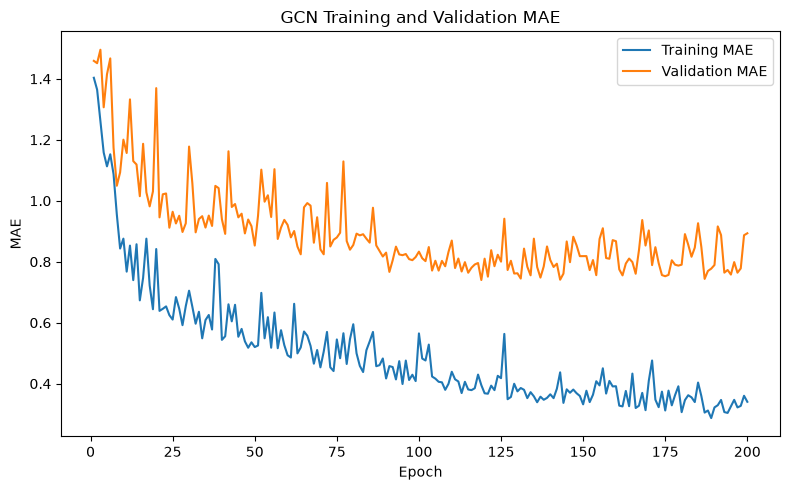

In [44]:
#=============================================================
# PLOT TRAINING CURVES
#=============================================================
plt.figure(figsize=(8, 5))
plt.plot(
    history_df["epoch"],
    history_df["train_mae"],
    label="Training MAE"
    )

plt.plot(
    history_df["epoch"],
    history_df["val_mae"],
    label="Validation MAE"
)

plt.xlabel('Epoch')
plt.ylabel('MAE')
plt.title("GCN Training and Validation MAE")
plt.legend()
plt.tight_layout()

plt.savefig("results/training_curves.png", dpi=300)
#plt.close()
plt.show()

In [45]:
#================================================
# LOAD BEST MODEL
#================================================
model.load_state_dict(
    torch.load(
        "models/best_gcn.pt",
        map_location=DEVICE
    )
)

print("\n Best epoch: ", best_epoch)
print("Best validation MAE: ", best_val_mae)


 Best epoch:  119
Best validation MAE:  0.739952027797699


In [46]:
#=====================================
# TEST
#=====================================
test_mae, test_rmse, test_r2, test_predictions, test_targets = evaluate(test_loader)

print("\n FINAL GCN TEST RESULTS")
print("-----------------------------")
print("Test MAE: ", test_mae)
print("Test RMSE:", test_rmse)
print("Test R2: ", test_r2)

#========================================================
# SAVE METRICS
#========================================================
metrics_df = pd.DataFrame([{
    "model" : "GCN",
    "best_epoch" : best_epoch,
    "test_mae" : test_mae,
    "test_rmse" : test_rmse,
    "test_r2" : test_r2
}])


 FINAL GCN TEST RESULTS
-----------------------------
Test MAE:  0.8661502003669739
Test RMSE: 1.1193564108748608
Test R2:  0.6467177867889404


In [47]:
metrics_df.to_csv(
    "results/gcn_metrics.csv",
    index=False
)

In [49]:
# ============================================================
# 17. SAVE PREDICTIONS
# ============================================================

test_smiles = [
    smiles_list[i]
    for i in test_idx
]

predictions_df = pd.DataFrame({
    "SMILES": test_smiles,
    "Experimental": test_targets,
    "Predicted": test_predictions,
    "Absolute_Error": np.abs(
        test_targets - test_predictions
    )
})

predictions_df.to_csv(
    "results/gcn_test_predictions.csv",
    index=False
)


In [50]:
# ============================================================
# 18. PREDICTION PLOT
# ============================================================

plt.figure(figsize=(6, 6))

plt.scatter(
    test_targets,
    test_predictions
)

low = min(
    test_targets.min(),
    test_predictions.min()
)

high = max(
    test_targets.max(),
    test_predictions.max()
)

plt.plot(
    [low, high],
    [low, high],
    linestyle="--"
)

plt.xlabel("Experimental Solubility")
plt.ylabel("Predicted Solubility")
plt.title("GCN: Experimental vs Predicted")

plt.tight_layout()

plt.savefig(
    "results/gcn_prediction_plot.png",
    dpi=300
)

plt.close()

# ============================================================
# 19. ERROR ANALYSIS
# ============================================================

predictions_df = predictions_df.sort_values(
    "Absolute_Error",
    ascending=False
)

predictions_df.to_csv(
    "results/gcn_test_predictions_sorted.csv",
    index=False
)

print("\nLargest test errors:")
print(
    predictions_df.head(10)
)

print("\nAll results saved in results/")


Largest test errors:
                                                SMILES  ...  Absolute_Error
16                             Cc1cc(=O)n(c2ccccc2)n1C  ...        3.669693
17                     CN(C)c2c(C)n(C)n(c1ccccc1)c2=O   ...        2.965932
104                                C1=Cc2cccc3cccc1c23  ...        2.721143
40   CC1OC(CC(O)C1O)OC2C(O)CC(OC2C)OC8C(O)CC(OC7CCC...  ...        2.556639
15                          Cc2c(N)c(=O)n(c1ccccc1)n2C  ...        2.400253
76   OC(C1=CC2C5C(C1C2=C(c3ccccc3)c4ccccn4)C(=O)NC5...  ...        2.282924
36                              CC2(C)C1CCC(C)(C1)C2=O  ...        2.099187
46                                    c2ccc1[nH]ccc1c2  ...        1.874180
26                                             c1ccoc1  ...        1.858177
80                           Nc2nc1[nH]cnc1c(=O)[nH]2   ...        1.823554

[10 rows x 4 columns]

All results saved in results/


In [51]:
from rdkit import DataStructs
from rdkit.Chem import rdFingerprintGenerator
from sklearn.ensemble import RandomForestRegressor

In [52]:
dataset = MoleculeNet(root="data/ESOL", name="ESOL")
smiles_list = list(dataset.smiles)
targets = dataset.data.y.view(-1).numpy()
print("Dataset size:", len(smiles_list))

Dataset size: 1128


C:\Users\mulpu\AppData\Local\Temp\ipykernel_37848\2727141023.py:3: UserWarning: It is not recommended to directly access the internal storage format `data` of an 'InMemoryDataset'. If you are absolutely certain what you are doing, access the internal storage via `InMemoryDataset._data` instead to suppress this warning. Alternatively, you can access stacked individual attributes of every graph via `dataset.{attr_name}`.
  targets = dataset.data.y.view(-1).numpy()


In [53]:
#===========================================
# LOAD THE SAME SPLIT
#===========================================
with open("results/split_indices.json", "r") as f:
    split_indices = json.load(f)

train_idx = split_indices["train"]
val_idx = split_indices["validation"]
test_idx = split_indices["test"]

In [56]:
#==================================================
# GENERATE MORGAN FINGERPRINTS
#==================================================

generator = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
fingerprints = []

for smiles in smiles_list:
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        raise ValueError(
            f"Invalid SMILES: {smiles}"
        )

    fp = generator.GetFingerprint(mol)

    arr = np.zeros((2048,), dtype=np.uint8)
    DataStructs.ConvertToNumpyArray(fp, arr)

    fingerprints.append(arr)

X = np.array(fingerprints)
y = targets

In [57]:
# ============================================================
# 4. DATA SPLITS
# ============================================================

X_train = X[train_idx]
y_train = y[train_idx]

X_val = X[val_idx]
y_val = y[val_idx]

X_test = X[test_idx]
y_test = y[test_idx]


In [58]:
# ============================================================
# 5. TRAIN RANDOM FOREST
# ============================================================

rf = RandomForestRegressor(
    n_estimators=500,
    max_features=0.7,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

rf.fit(
    X_train,
    y_train
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",500
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",0.7
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"m

In [59]:
# ============================================================
# 6. VALIDATION EVALUATION
# ============================================================

val_predictions = rf.predict(X_val)

val_mae = mean_absolute_error(
    y_val,
    val_predictions
)

val_rmse = np.sqrt(
    mean_squared_error(
        y_val,
        val_predictions
    )
)

val_r2 = r2_score(
    y_val,
    val_predictions
)

print("\nRF VALIDATION RESULTS")
print("-----------------------------")
print("Validation MAE:", val_mae)
print("Validation RMSE:", val_rmse)
print("Validation R2:", val_r2)


RF VALIDATION RESULTS
-----------------------------
Validation MAE: 1.1274788622666054
Validation RMSE: 1.4204992241531977
Validation R2: 0.52754513383092


In [63]:
# ============================================================
# 7. TEST EVALUATION
# ============================================================

test_predictions = rf.predict(X_test)

test_mae = mean_absolute_error(
    y_test,
    test_predictions
)

test_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        test_predictions
    )
)

test_r2 = r2_score(
    y_test,
    test_predictions
)

print("\nRF TEST RESULTS")
print("-----------------------------")
print("Test MAE:", test_mae)
print("Test RMSE:", test_rmse)
print("Test R2:", test_r2)



RF TEST RESULTS
-----------------------------
Test MAE: 1.0415971983671295
Test RMSE: 1.335279676276406
Test R2: 0.4972761929830598


In [64]:
# ============================================================
# 8. SAVE METRICS
# ============================================================

os.makedirs("results", exist_ok=True)
os.makedirs("models", exist_ok=True)

metrics_df = pd.DataFrame([{
    "model": "RandomForest_Morgan",
    "validation_mae": val_mae,
    "validation_rmse": val_rmse,
    "validation_r2": val_r2,
    "test_mae": test_mae,
    "test_rmse": test_rmse,
    "test_r2": test_r2
}])

metrics_df.to_csv(
    "results/rf_metrics.csv",
    index=False
)


In [65]:
# ============================================================
# 9. SAVE TEST PREDICTIONS
# ============================================================

test_smiles = [
    smiles_list[i]
    for i in test_idx
]

predictions_df = pd.DataFrame({
    "SMILES": test_smiles,
    "Experimental": y_test,
    "Predicted": test_predictions,
    "Absolute_Error": np.abs(
        y_test - test_predictions
    )
})

predictions_df.to_csv(
    "results/rf_test_predictions.csv",
    index=False
)


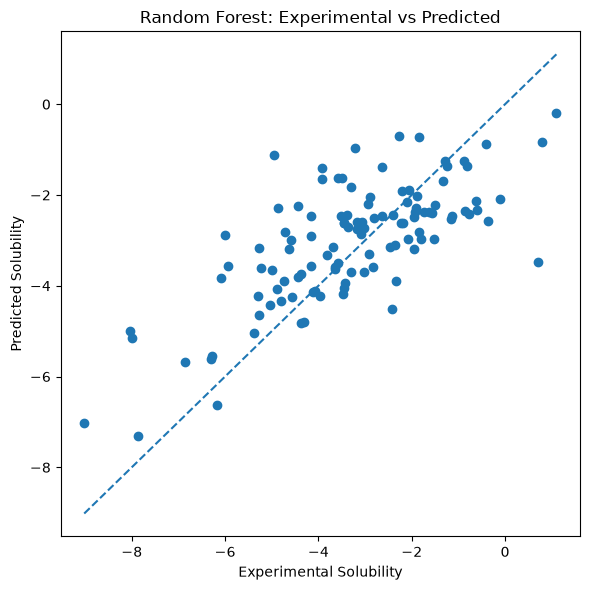

In [74]:
# ============================================================
# 10. PREDICTION PLOT
# ============================================================

plt.figure(figsize=(6, 6))

plt.scatter(
    y_test,
    test_predictions
)

low = min(
    y_test.min(),
    test_predictions.min()
)

high = max(
    y_test.max(),
    test_predictions.max()
)

plt.plot(
    [low, high],
    [low, high],
    linestyle="--"
)


plt.xlabel("Experimental Solubility")
plt.ylabel("Predicted Solubility")

plt.title(
    "Random Forest: Experimental vs Predicted"
)

plt.tight_layout()

plt.savefig(
    "results/rf_prediction_plot.png",
    dpi=300
)

In [75]:

# ============================================================
# 11. SAVE MODEL
# ============================================================

import joblib

joblib.dump(
    rf,
    "models/random_forest.pkl"
)

print("\nRandom Forest results saved.")


Random Forest results saved.
